# Phân tích và dự đoán bệnh tim mạch

# Phần 1. Khám phá dữ liệu

#### 1.1. Đọc dữ liệu và xem phân bố

In [30]:
import pandas as pd
import matplotlib.pyplot as mpl
import seaborn as sb

# Đọc file
dataset_sach = pd.read_csv("cleaned_cardio.csv")

In [31]:
# .shape trả về (số hàng, số cột) của bảng dữ liệu
print("Kích thước dữ liệu:", dataset_sach.shape)

# .columns.tolist() lấy tên các cột và chuyển thành list
print("\nCác cột:")
dataset_sach.columns


Kích thước dữ liệu: (59187, 13)

Các cột:


Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio'],
      dtype='object')

In [32]:
dataset_sach.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,50,2,168,62.0,110,80,1,1,0,0,1,0
1,1,55,1,156,85.0,140,90,3,1,0,0,1,1
2,2,52,1,165,64.0,130,70,3,1,0,0,0,1
3,3,48,2,169,82.0,150,100,1,1,0,0,1,1
4,8,60,1,151,67.0,120,80,2,2,0,0,0,0


In [33]:
dataset_sach.tail()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
59182,99991,54,1,172,70.0,130,90,1,1,0,0,1,1
59183,99992,58,1,165,80.0,150,80,1,1,0,0,1,1
59184,99993,53,2,168,76.0,120,80,1,1,1,0,1,0
59185,99998,61,1,163,72.0,135,80,1,2,0,0,0,1
59186,99999,56,1,170,72.0,120,80,2,1,0,0,1,0


**Hai nhóm có bao nhiêu người?** Bảng cho biết tỷ lệ phần trăm, còn chiều cao của cột cho biết số người.

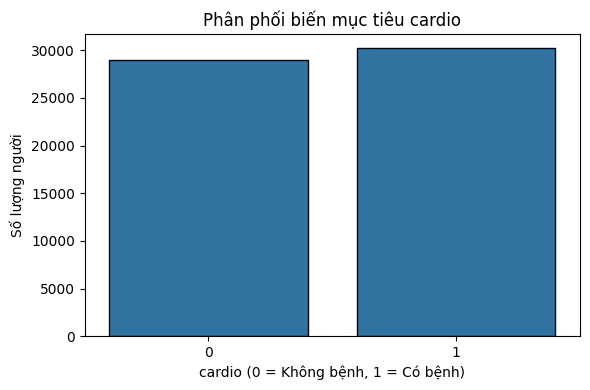

In [34]:
# Phân phối biến mục tiêu cardio
fig, axes = mpl.subplots(1, 1, figsize=(6, 4))

sb.countplot(data=dataset_sach, x="cardio", ax=axes, edgecolor="black")

axes.set_title("Phân phối biến mục tiêu cardio")
axes.set_xlabel("cardio (0 = Không bệnh, 1 = Có bệnh)")
axes.set_ylabel("Số lượng người")

mpl.tight_layout()
mpl.show()

**Các chỉ số tập trung ở khoảng nào?** Mỗi cột trong histogram đếm số người thuộc một khoảng giá trị.

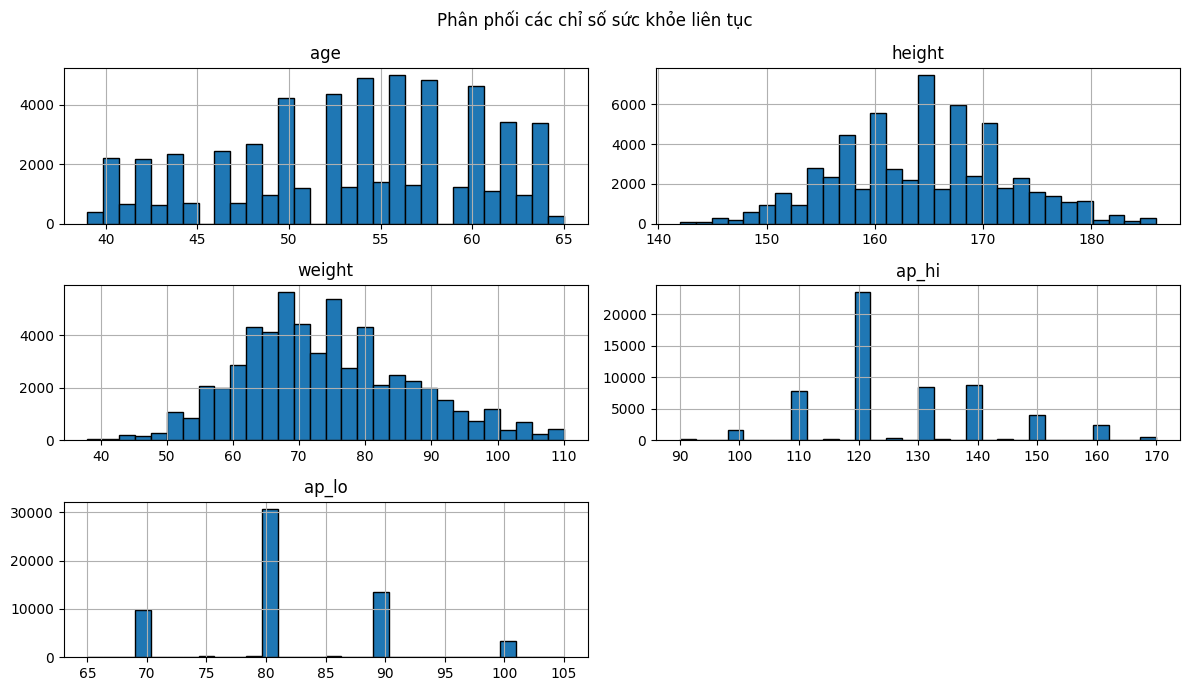

In [35]:
# Histogram phân phối các chỉ số thể chất và sức khỏe

# Danh sách các cột số liên tục cần vẽ
continuous_columns = ["age", "height", "weight", "ap_hi", "ap_lo"]

# Lấy riêng các cột cần vẽ ra một bảng nhỏ
continuous_data = dataset_sach[continuous_columns]

# .hist() vẽ một histogram cho mỗi cột
# bins=20: chia dữ liệu thành 20 khoảng; edgecolor="black": viền đen cho mỗi cột
continuous_data.hist(figsize=(12, 7), bins=30, edgecolor="black")

# suptitle() đặt tiêu đề chung cho cả hình
mpl.suptitle("Phân phối các chỉ số sức khỏe liên tục")

# tight_layout() tự căn khoảng cách để các biểu đồ con không đè lên nhau
mpl.tight_layout()
mpl.show()

#### 1.2. So sánh người có bệnh và không có bệnh

Đường giữa mỗi hộp là trung vị. So sánh hai đường này để xem chỉ số nào thường cao hơn ở nhóm có bệnh.

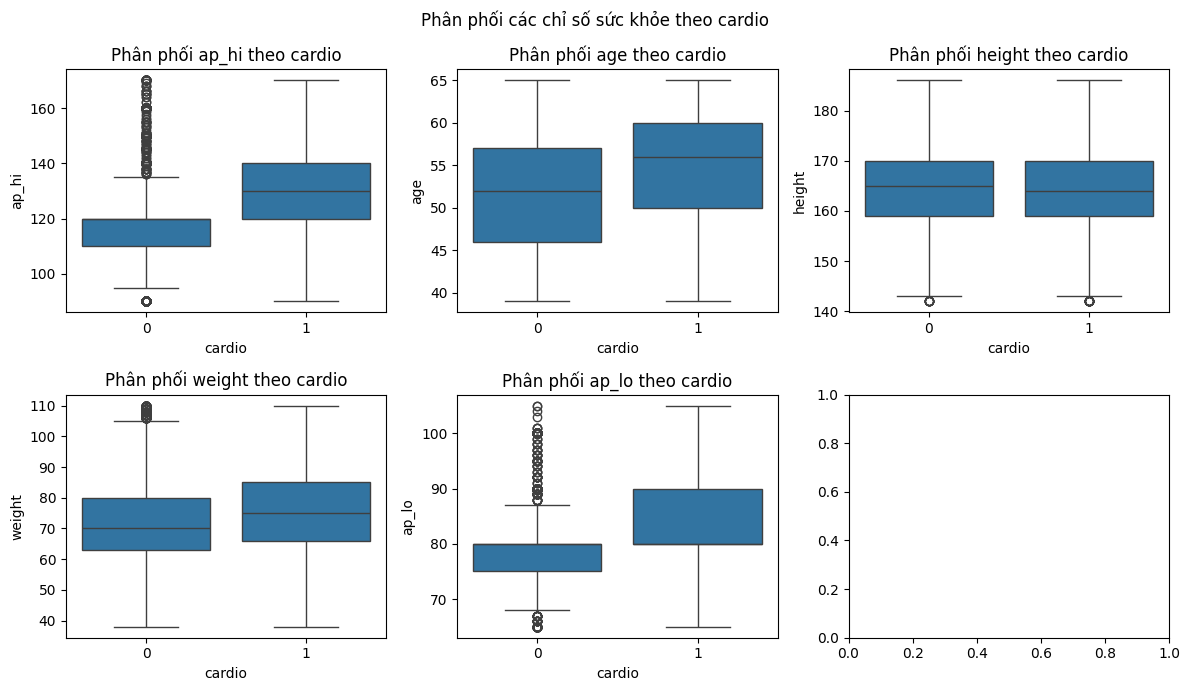

In [36]:
# Danh sách các cột số liên tục cần vẽ
numeric_columns = ["ap_hi", "age", "height", "weight", "ap_lo"]

# Tạo khung hình gồm 2 hàng, 3 cột
fig, axes = mpl.subplots(2, 3, figsize=(12, 7))

# Chuyển mảng 2 chiều thành mảng 1 chiều
axes = axes.flatten()

for i in range(0, 5):
    cot = numeric_columns[i]

    # Vẽ biểu đồ Boxplot theo cardio
    sb.boxplot(data=dataset_sach, x="cardio", y=cot, ax=axes[i])

    # Đặt tiêu đề và tên trục
    axes[i].set_title("Phân phối " + cot + " theo cardio")
    axes[i].set_xlabel("cardio")
    axes[i].set_ylabel(cot)

# Tiêu đề chung
mpl.suptitle("Phân phối các chỉ số sức khỏe theo cardio")

mpl.tight_layout()
mpl.show()

**Các đặc điểm còn lại.** Biểu đồ này đếm số người. Khi hai nhóm có quy mô khác nhau, cần so sánh tỷ lệ trước khi kết luận nhóm nào thường mắc bệnh hơn.

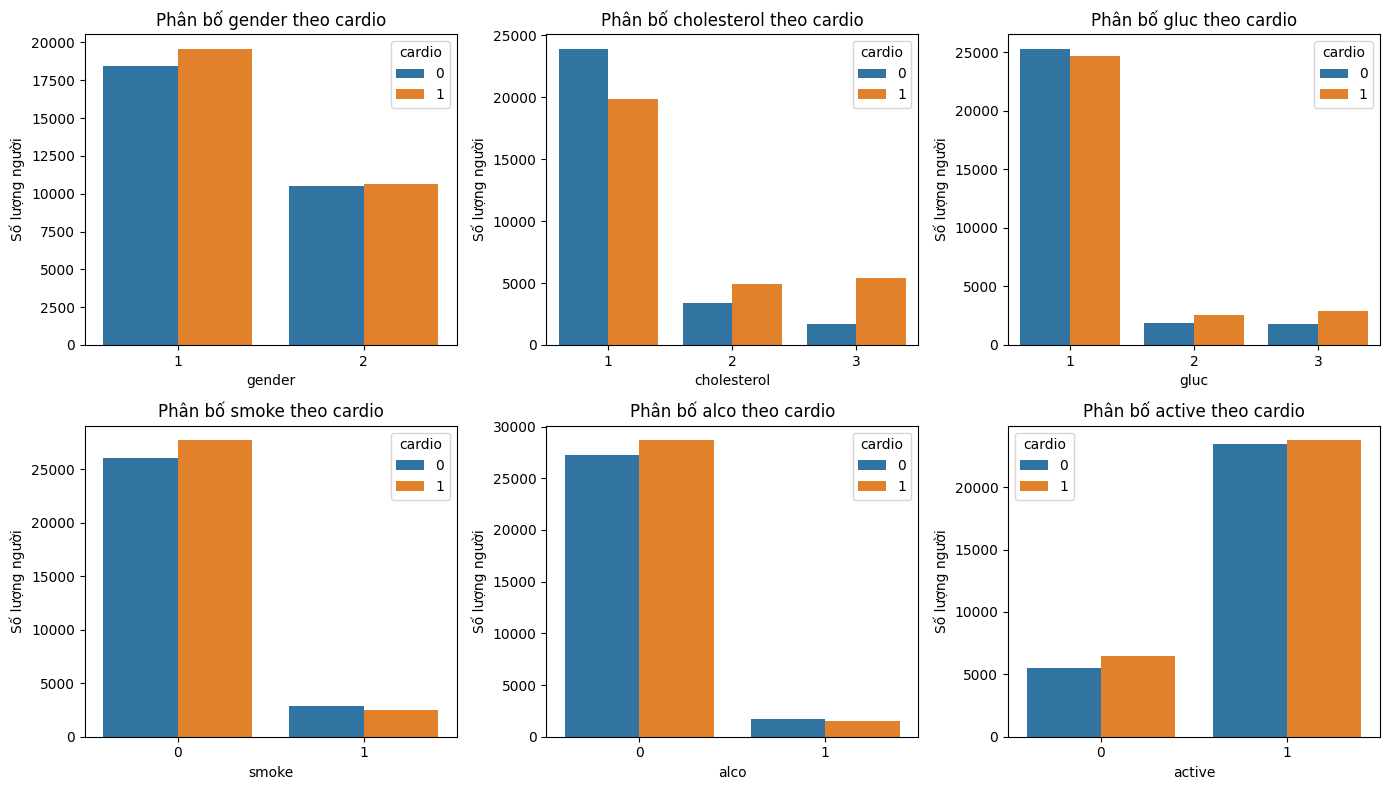

In [37]:
# Phân bố các biến phân loại và thói quen sinh hoạt theo cardio
category_columns = ["gender", "cholesterol", "gluc", "smoke", "alco", "active"]

# Tạo hình gồm 2 hàng x 3 cột = 6 ô biểu đồ
fig, axes = mpl.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i in range(0, 6):
    column_name = category_columns[i]

    current_axis = axes[i]

    # Đếm số người theo từng giá trị của cột, tách màu theo nhãn cardio
    sb.countplot(data=dataset_sach, x=column_name, hue="cardio", ax=current_axis)

    chart_title = "Phân bố " + column_name + " theo cardio"
    current_axis.set_title(chart_title)
    current_axis.set_xlabel(column_name)
    current_axis.set_ylabel("Số lượng người")

mpl.tight_layout()
mpl.show()

#### 1.3. Chỉ số nào có tương quan với nhãn bệnh?

Hệ số dương cho biết hai biến có xu hướng tăng cùng nhau. Bỏ qua đường chéo vì mỗi biến được so với chính nó.

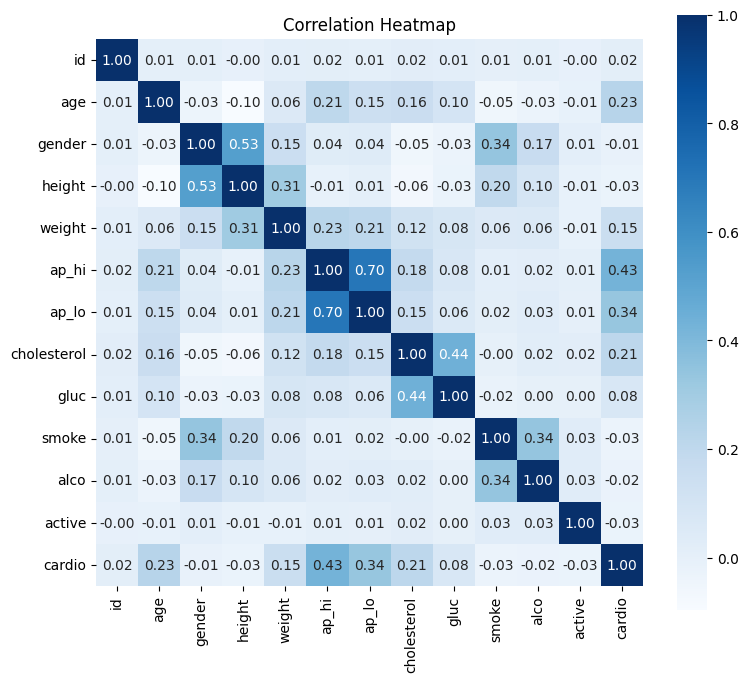

In [38]:
# Tính ma trận tương quan giữa các biến số

# Bước 1: select_dtypes(include="number") chỉ giữ lại các cột kiểu số
numeric_data = dataset_sach.select_dtypes(include="number")

# Bước 2: .corr() tính hệ số tương quan giữa từng cặp cột
correlation_matrix = numeric_data.corr()

# Vẽ Heatmap trực quan
mpl.figure(figsize=(8, 8))

# annot=True: ghi số lên mỗi ô
# fmt=".2f": hiện 2 chữ số thập phân
# square=True: ô hình vuông
# cbar_kws={"shrink": 0.8}: thanh màu thu nhỏ còn 80% so với bảng
sb.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="Blues", square=True, cbar_kws={"shrink": 0.8})
mpl.title("Correlation Heatmap")
mpl.tight_layout()
mpl.show()

Đọc cột tương quan với `cardio`. Bỏ qua `id` vì đây chỉ là mã bản ghi.

In [39]:
# Bước 1: Lấy cột "cardio" trong ma trận tương quan
cardio_correlation = correlation_matrix["cardio"]

# Bước 2: Xóa cột active và id
cardio_correlation = cardio_correlation.drop(["active", "id"])

# Bước 3: Sắp xếp giảm dần
cardio_correlation = cardio_correlation.sort_values(ascending=False)

cardio_correlation

cardio         1.000000
ap_hi          0.429538
ap_lo          0.335058
age            0.231855
cholesterol    0.209871
weight         0.154334
gluc           0.075879
gender        -0.012463
alco          -0.019457
height        -0.026492
smoke         -0.030206
Name: cardio, dtype: float64

**Nhận xét từ kết quả đã lưu.** Huyết áp tâm thu (`ap_hi`, 0,43) và tâm trương (`ap_lo`, 0,34) có tương quan dương cao nhất với nhãn bệnh trong các chỉ số được xét. Đây là mối liên hệ quan sát được trong bộ dữ liệu.